# What does deterministic scenario re-planning add?

**Question:** How much does a cheap deterministic re-solve improve on the best plan fixed before each geological draw?

**Level:** 3 — State of the art

**Prerequisites:** Complete uncertainty lessons 01 and 02 first.

**Reading time:** 24 minutes

## Objectives

This lesson implements the scenario-by-scenario deterministic practice described by Blom, Pearce and Cote, then measures what that practice can establish on a small PhaseFlow case. It asks a narrower question than stochastic optimization: after observing each synthetic value draw, how much does a deterministic Gershon schedule with shift search improve on the best plan committed before observing any draw? You will build the same declared case as the prior lessons, retain multiple fixed candidates, solve once per draw, and compare paired discounted values. The per-draw method is a heuristic, so its result supplies a lower bound on re-planning value, not the value of perfect information. Reproducing an industry practice does not make this toy experiment a production-grade stochastic model.

## Setup

Install the pinned method package for this lesson from the repository root. The imports cell reports the active versions; no notebook cell installs packages.

```bash
pip install oreblocks==0.6.3
```

In [1]:
# Import the pipeline and package APIs used in the lesson.
import dataclasses
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.3
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

The PhaseFlow MIT-licensed teaching pipeline builds a declared synthetic vein (4×4×3 blocks, seed 31, four periods, 8% discount). The value ensemble contains 24 equally weighted, spatially correlated synthetic draws from OreBlocks 0.6.3, using sigma 0.25, a two-block smoothing scale, and seed 19. These are not conditional simulations and contain no drillhole conditioning. The same resource, precedence, discount and horizon inputs are held fixed across draws; only block values change. Therefore, the experiment isolates value changes and cannot support claims about uncertain tonnage, costs, capacity, or actual geological probabilities.

## Method

For a period assignment τ and value vector v, discounted value is V(τ,v)=Σ[b:τ_b≥0]v_b(1+ρ)^(-τ_b). Before uncertainty is observed, a decision maker must choose one τ; its expected score is the average over draws. Scenario practice instead solves a separate deterministic problem for each vᵏ, producing τᵏ, and evaluates each τᵏ on its own draw. We use the Gershon successor-weight schedule with shift local search because it is inexpensive enough to repeat. `bound=False` deliberately skips the costly certified relaxation; consequently these re-solves are feasible heuristics and are not optimality certificates. For each draw, the comparison baseline is the best-scoring member of the fixed candidate set. Taking max(re-solve, fixed-set best) prevents a weaker heuristic from producing a negative apparent benefit. The mean paired difference is thus a non-negative heuristic lower bound on the value of adapting. True EVPI requires a proven optimum for every draw; a two-stage stochastic model also optimizes strategic decisions jointly across scenarios. Neither is computed here.

### Step 1: build the declared case

Declare the exact 48-block teaching case used in lessons 01 and 02, then build it through PhaseFlow's named pipeline. The contract report and block count let you detect input drift before attributing a result to uncertainty. The scenario definition, rather than a baked schedule, is the input to every method below.

In [2]:
# Build the declared synthetic case through the product pipeline.
case = Case(
    id='uncertainty-vein-4x4x3', category='teaching',
    title_en='Small synthetic vein', title_es='Veta sintetica pequena',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contract accepted:', instance.report.ok, '| blocks:', instance.n_blocks)

contract accepted: True | blocks: 48


### Step 2: prepare the reference and fixed menu

Solve the forecast case once with the package's expected-time procedure. This is the plan available before geological outcomes are known. Retaining the whole candidate alongside two alternative package schedules gives the decision maker a finite, explicitly defined menu; it is not the set of every feasible plan.

In [3]:
# Compute forecast and alternate fixed candidates before observing draws.
forecast, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='expected',
    local_search=True,
)
gershon_fixed, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='gershon',
    local_search=True,
)
greedy_fixed, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='greedy',
    local_search=True,
)
print(forecast.method, round(forecast.npv, 2))
print(gershon_fixed.method, round(gershon_fixed.npv, 2))
print(greedy_fixed.method, round(greedy_fixed.npv, 2))

toposort:expected[r1]+shift-ls 179191.57
toposort:gershon+shift-ls -74237.99
toposort:greedy+shift-ls 179593.14


### Step 3: generate common realisations

Generate the seeded ensemble through the package API. The same values are reused in every later cell, which makes comparisons paired: differences cannot be explained by one method receiving easier draws. Confirm the draw count and seed as part of the evidence trail.

In [4]:
# Generate a reproducible ensemble through the package API.
ensemble = ob.perturb_values(
    instance.cpit.value, instance.x, instance.y, instance.level,
    n=24, sigma=0.25, correlation_blocks=2.0, seed=19,
)
print('realisations:', ensemble.n_realisations, '| seed:', ensemble.seed)

realisations: 24 | seed: 19


### Step 4: score the fixed menu before re-planning

Evaluate every fixed candidate against every draw. This produces a method-by-realisation matrix without re-optimization. Its best entry per column is the opportunity available from selecting among this finite menu after seeing a draw; it is a stricter baseline than choosing only the forecast plan, yet weaker than a per-draw optimum.

In [5]:
# Score every fixed candidate on every shared value draw.
fixed_schedules = {
    forecast.method: forecast.period_of_block,
    gershon_fixed.method: gershon_fixed.period_of_block,
    greedy_fixed.method: greedy_fixed.period_of_block,
}
fixed_scores = ob.evaluate_across(
    instance.cpit, ensemble, fixed_schedules,
)
print('best by mean:', fixed_scores.best_by_expected)
print('best fixed mean:', round(float(fixed_scores.expected.max()), 2))

best by mean: toposort:expected[r1]+shift-ls
best fixed mean: 173035.23


### Step 5: solve a deterministic instance per realisation

For each draw, replace only the CPIT value vector and invoke the documented Gershon schedule with shift search. Skipping the bound avoids computing a certificate that this re-planning comparison does not use. The output keeps each schedule, its draw-specific score, and the candidate-set score together so the pairing is auditable.

## State of the art

Blom, Pearce and Cote describe solving many deterministic instances as mining practice for strategic decisions under uncertainty. This lesson runs that pattern: each scenario receives a deterministic solve and all outputs are compared using paired discounted values. Gershon with shift search is a heuristic available in OreBlocks; it is not the stochastic optimization method of Ramazan and Dimitrakopoulos. The call skips the expensive bound and establishes only feasibility under the supplied constraints.

In [6]:
# Re-solve each value realisation with a cheap feasible heuristic.
replanned = []
for draw_values in ensemble.values:
    draw_cpit = dataclasses.replace(instance.cpit, value=draw_values)
    schedule, _ = ob.solve_cpit(
        draw_cpit, instance.precedence, method='gershon',
        local_search=True, bound=False,
    )
    replanned.append(schedule)
replan_values = np.array([item.npv for item in replanned])
print('re-solves:', len(replanned), '| first:', round(float(replan_values[0]), 2))

re-solves: 24 | first: -71365.64


### Step 6: calculate paired gain and its bound

Choose the fixed candidate with the highest mean before observing draws; that row is the ex-ante baseline. For each draw, allow recourse to take the better of the heuristic re-solve and the best plan in the finite menu. The average recourse-minus-baseline difference is non-negative by the max-of-expectations inequality. Individual draws may be negative. This is a feasible lower bound on the value of information for this menu and heuristic; it is not EVPI.

In [7]:
# Compare scenario recourse with the best ex-ante fixed candidate.
best_fixed_index = int(np.argmax(fixed_scores.expected))
fixed_ex_ante = fixed_scores.matrix[best_fixed_index]
fixed_best_by_draw = fixed_scores.matrix.max(axis=0)
recourse_values = np.maximum(replan_values, fixed_best_by_draw)
paired_gain = recourse_values - fixed_ex_ante
replan_result = ob.evaluate_across(
    instance.cpit, ensemble, fixed_schedules,
    per_realisation_optimum=recourse_values,
)
print('mean lower bound:', round(replan_result.value_of_replanning, 2))
print('P10/P90:', round(float(np.quantile(paired_gain, 0.10)), 2),
      round(float(np.quantile(paired_gain, 0.90)), 2))
print('positive draws:', int(np.count_nonzero(paired_gain > 1e-9)), '/', len(paired_gain))

mean lower bound: 658.85
P10/P90: 0.0 2199.7
positive draws: 12 / 24


### Distribution comparison

The left panel compares the forecast plan, the best fixed-menu plan by mean, and the heuristic re-solve score on identical draws. The right panel shows the paired improvement over the menu. The first panel exposes distribution and tail behavior; the second makes zero-gain scenarios visible rather than hiding them in an average. These 24 points are a designed experiment, not inferential samples from a calibrated deposit model.

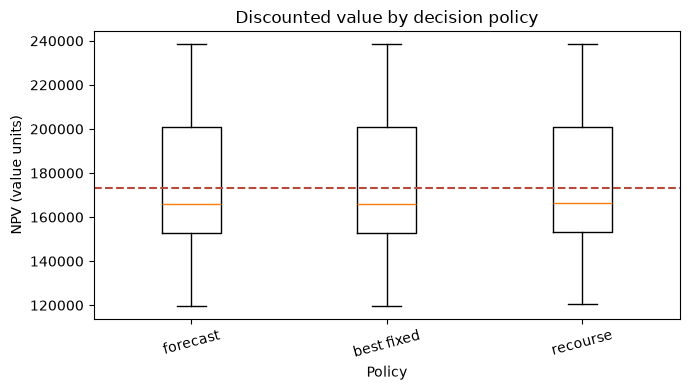

In [8]:
# Compare fixed policies with the value available through scenario recourse.
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([fixed_scores.matrix[0], fixed_ex_ante, recourse_values],
    tick_labels=['forecast', 'best fixed', 'recourse'])
ax.axhline(fixed_scores.expected.max(), color='#b64b3b', linestyle='--')
ax.set(title='Discounted value by decision policy',
    xlabel='Policy', ylabel='NPV (value units)')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()

### Figure 1

Each box summarizes discounted values on the same 24 synthetic draws. The forecast and best-fixed boxes keep one schedule across every draw; recourse may choose the better of a re-solve and the finite menu after seeing the draw. The dashed line marks the ex-ante best fixed plan's mean, not a benchmark optimum. Medians and spread describe this seeded experiment only. Overlap is not a significance test, and P10 is not a guaranteed floor. This figure does not validate the synthetic geology or feasibility beyond the supplied constraints.

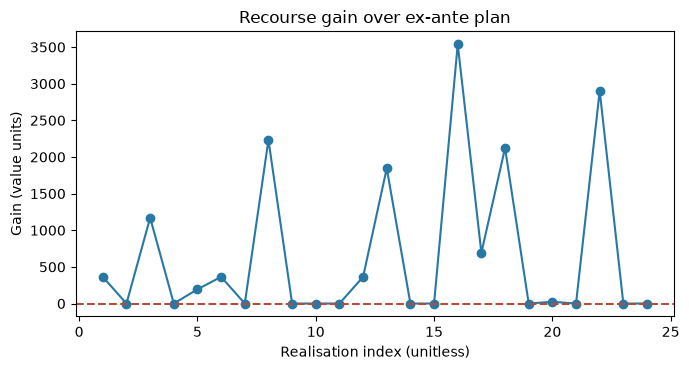

In [9]:
# Plot recourse gains and the zero-gain reference for every draw.
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(1, len(paired_gain) + 1), paired_gain,
    marker='o', color='#2878a5')
ax.axhline(0, color='#b64b3b', linestyle='--')
ax.set(title='Recourse gain over ex-ante plan',
    xlabel='Realisation index (unitless)', ylabel='Gain (value units)')
fig.tight_layout()
plt.show()

### Figure 2

Each point is recourse value minus the per-draw score of the one plan selected ex ante by highest mean. Recourse can be below that plan on an individual draw, shown relative to the zero line, although its average cannot be negative because the decision maker can select among feasible candidates after observing a draw. The mean is a lower bound for this menu and heuristic. It is not EVPI: the heuristic may miss better schedules and the menu omits many feasible plans.

## Results

**Answer:** Scenario recourse averages **658.85 value units** above the best ex-ante fixed plan (P10 0.00, P90 2199.70; positive gain in 12 of 24 draws). This lower bound combines the per-draw re-solve with selection from the finite candidate menu; it is not EVPI. The figures show the same paired comparison.

In [10]:
# Print the computed metrics quoted in the answer.
print(f'mean_gain={paired_gain.mean():.2f}')
print(f'P10={np.quantile(paired_gain, 0.10):.2f}; P90={np.quantile(paired_gain, 0.90):.2f}')
print(f'improved_draws={(paired_gain > 1e-9).mean():.3f}')

mean_gain=658.85
P10=0.00; P90=2199.70
improved_draws=0.500


## Summary

The experiment follows the deterministic scenario-analysis practice in the cited mining literature: solve each realization and compare resulting plans on common scenarios. The method can reveal whether a cheap adaptation reacts to this generator better than a small menu fixed in advance. Its conclusion is bounded by the 48-block synthetic case, 24 equally weighted draws, fixed tonnage and capacity, and a heuristic re-solve without a certificate. A serious study needs conditional simulations with provenance, calibrated scenario weights, uncertainty in relevant inputs, robust operational checks, and stronger optimization. To claim EVPI, supply an optimality-proven solve for each draw; to claim a stochastic-program result, model the shared strategic decisions across scenarios.

## References

- Blom, Pearce and Cote, stochastic optimization in practice: https://arxiv.org/abs/2403.18213.
- Ramazan and Dimitrakopoulos, two-stage stochastic integer programming: https://doi.org/10.1007/s11081-012-9186-2.
- OreBlocks 0.6.3, `solve_cpit`, `perturb_values` and `evaluate_across`: https://pypi.org/project/oreblocks/0.6.3/.
- PhaseFlow instance schema and builder: `data-pipeline/pipeline/io/schema.py` and `data-pipeline/pipeline/model/instances.py` (MIT).